# Model a push-pull traveling-wave MZM with Circulax

Build an optical Mach–Zehnder modulator, add differential/common-mode electrodes, then place it between grating couplers and simulate a **56 Gbaud eye**. Both PN phase shifters are circuit components: their solved junction voltages control optical phase, and native history reads supply optical propagation delay.

We use illustrative parameters, constant optical loss and constant junction capacitance. The phase law is quadratic in voltage. Use the Circulax checkout containing `DifferentialAdapter` and `mode_transmission_line`.

The workflow is **define components → connect a circuit → compile → solve → inspect the result**. Detailed S-parameter fitting and voltage-integration comparisons live in the separate [validation notebook](traveling_wave_mzm_validation.ipynb).

In [1]:
import copy
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from circulax import compile_circuit
from circulax.components import DifferentialAdapter, mode_transmission_line
from circulax.components.base_component import component
from circulax.components.electronic import (
    WAVE_DC,
    WAVE_PWL,
    WAVE_SIN,
    Capacitor,
    Resistor,
    WaveformVoltageSource,
)
from circulax.components.photonic import DirectionalCoupler, Grating, OpticalSource

jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True})
c0 = 299_792_458.0
length_m, n_sections = 2e-3, 6
dz = length_m / n_sections
n_opt, wavelength_um, optical_loss_db_cm = 4.05, 1.55, 1.0
rj_product, cj_per_m = 4.7e-3, 320e-12  # ohm m, F/m
v_bias, phase_a1, phase_a2 = -1.0, 1.2, 0.15  # V, rad/(V mm), rad/(V² mm)
source_r = load_r = 30.0  # per conductor, ohms
laser_power, grating_loss_db = 1e-3, 3.0  # W, dB per grating
quadrature_phase = -np.pi / 2
print(f"{n_sections} sections: {dz * 1e6:.1f} um, Rj={rj_product / dz:.2f} ohm, Cj={cj_per_m * dz * 1e15:.1f} fF")

6 sections: 333.3 um, Rj=14.10 ohm, Cj=106.7 fF


## 1. Build the optical MZM and set quadrature

Use two 50/50 directional couplers as splitter and combiner. Their unused ports receive matched 1 Ω optical-envelope loads. A simple bidirectional phase shifter provides a separate bias adjustment:

```text
                         arm A
                  ┌──────────────────┐
optical in ─ splitter                combiner ─ optical out
                  └──── arm B ─ bias ┘
```

First use constant-phase elements for both arms. With this coupler wiring the selected output has $P_\mathrm{out}/P_\mathrm{in}=[1-\cos(\theta)]/2$ when the arms are equal. Sweep the bias phase and verify that $\theta=-\pi/2$ gives half transmission. The other output carries the complementary power.

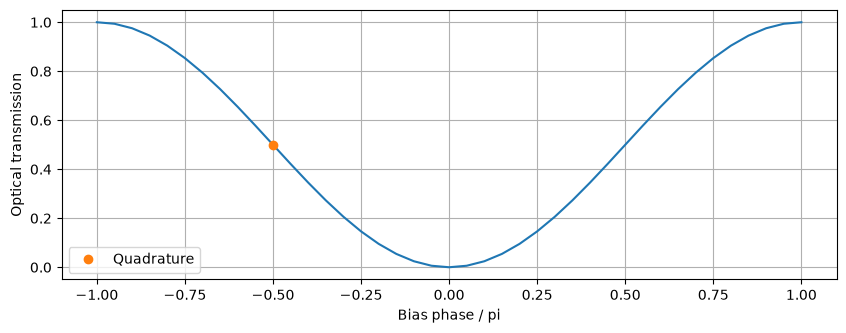

In [2]:
@component(ports=("p1", "p2"), states=("a1", "a2"), holomorphic=True)
def PhaseBias(signals, phase=0.0):  # noqa: N802
    """Matched, reciprocal phase-only optical element; field impedance is 1 ohm."""
    transmission = jnp.exp(1j * phase)
    b1, b2 = transmission * signals.a2, transmission * signals.a1
    return {
        "p1": signals.a1 - b1,
        "p2": signals.a2 - b2,
        "a1": signals.p1 - signals.a1 - b1,
        "a2": signals.p2 - signals.a2 - b2,
    }, {}


def optical_netlist():
    return {
        "instances": {
            "GND": {"component": "ground"},
            "SPLIT": {"component": "coupler", "settings": {"coupling": 0.5}},
            "COMBINE": {"component": "coupler", "settings": {"coupling": 0.5}},
            "ARM_A": {"component": "bias"},
            "ARM_B": {"component": "bias"},
            "BIAS": {"component": "bias", "settings": {"phase": quadrature_phase}},
            "DUMP_IN": {"component": "R", "settings": {"R": 1.0}},
            "DUMP_OUT": {"component": "R", "settings": {"R": 1.0}},
        },
        "connections": {
            "SPLIT,p2": "DUMP_IN,p1",
            "DUMP_IN,p2": "GND,p1",
            "DUMP_OUT,p2": "GND,p1",
            "SPLIT,p3": "ARM_A,p1",
            "SPLIT,p4": "ARM_B,p1",
            "ARM_A,p2": "COMBINE,p1",
            "ARM_B,p2": "BIAS,p1",
            "BIAS,p2": "COMBINE,p2",
            "COMBINE,p4": "DUMP_OUT,p1",
        },
        "ports": {"optical_in": "SPLIT,p1", "optical_out": "COMBINE,p3"},
    }


optical_models = {"coupler": DirectionalCoupler, "bias": PhaseBias, "R": Resistor}
simple_mzm = compile_circuit(optical_netlist(), optical_models, is_complex=True)
static_net = {
    "instances": {
        "GND": {"component": "ground"},
        "MZM": {"component": "mzm"},
        "LASER": {"component": "laser", "settings": {"power": laser_power}},
        "LOAD": {"component": "R", "settings": {"R": 1.0}},
    },
    "connections": {"LASER,p1": "MZM,optical_in", "LASER,p2": "GND,p1", "MZM,optical_out": "LOAD,p1", "LOAD,p2": "GND,p1"},
    "ports": {"output": "LOAD,p1"},
}
static = compile_circuit(static_net, {"mzm": simple_mzm, "laser": OpticalSource, "R": Resistor}, is_complex=True)
phases = jnp.linspace(-np.pi, np.pi, 41)
static_solution = static.dc(params={"MZM~BIAS.phase": phases})
transmission = np.abs(np.asarray(static.port(static_solution, "output"))) ** 2 / laser_power
np.testing.assert_allclose(transmission, (1 - np.cos(phases)) / 2, atol=1e-7)
plt.plot(phases / np.pi, transmission)
plt.plot(-0.5, 0.5, "o", label="Quadrature")
plt.xlabel("Bias phase / pi")
plt.ylabel("Optical transmission")
plt.legend()
plt.show()

## 2. Define the differential and common-mode electrodes

A uniform symmetric coupled pair can be described by frequency-dependent attenuation, RF effective index and characteristic impedance for each mode. These may come from a 2D RF mode solve. Use full differential/common quantities:

$$V_d=V_a-V_b,\quad V_c=(V_a+V_b)/2,\qquad
I_d=(I_a-I_b)/2,\quad I_c=I_a+I_b.$$

The impedances are $Z_d=2Z_\mathrm{odd}$ and $Z_c=Z_\mathrm{even}/2$ if your extraction provides per-conductor odd/even values. Two separate 30 Ω conductor terminations become **60 Ω differential and 15 Ω common mode**.

For each mode, `mode_transmission_line` accepts functions, scalars or sampled arrays on the supplied frequency grid:

| Input | Meaning | Unit |
| --- | --- | --- |
| `attenuation_db_per_m` | Attenuation per unit length | dB/m |
| `n_eff` | Real RF phase effective index | dimensionless |
| `impedance` | Modal characteristic impedance; may be complex | Ω |

The factory forms $\gamma=\ln(10)\,\alpha_\mathrm{dB/m}/20+j2\pi f n_\mathrm{eff}/c$, then builds the passive, causal RLC approximation. Its fit tolerance and spatial discretization remain explicit.

The example functions below are smooth, mutually consistent **bare-electrode** data. The PN resistance and capacitance are added in the next section. If your mode solve already includes them, omit that explicit electrical loading while retaining the optical phase response; otherwise they are counted twice. This distinction also applies to [mode-solver workflows](https://optics.ansys.com/hc/en-us/articles/360042328774-Traveling-Wave-Mach-Zehnder-Modulator).

Differential fit NRMSE: series 0.026%, shunt 0.026%
Common fit NRMSE: series 0.019%, shunt 0.019%


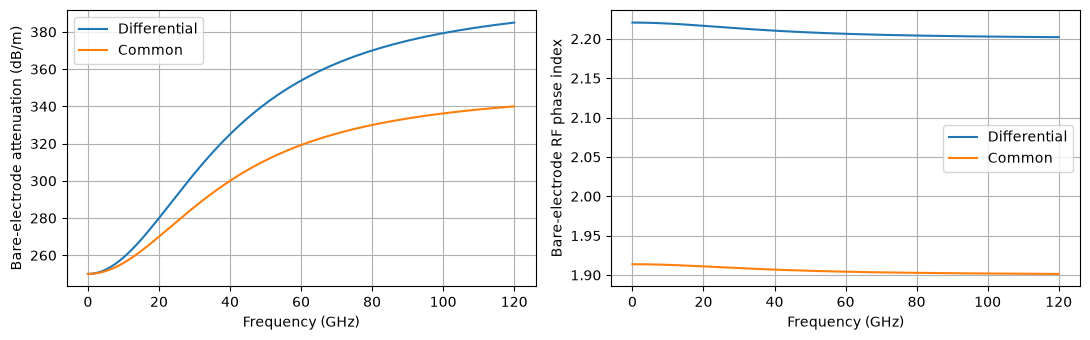

In [3]:
frequencies = np.r_[0.0, np.geomspace(1e7, 120e9, 200)]


def attenuation_d(f_hz):
    """Illustrative differential-mode attenuation, in dB/m."""
    x = f_hz / 40e9
    return 250.0 + 150.0 * x**2 / (1 + x**2)


def neff_d(f_hz):
    return 2.2 + 0.0206 / (1 + (f_hz / 40e9) ** 2)


def attenuation_c(f_hz):
    x = f_hz / 40e9
    return 250.0 + 100.0 * x**2 / (1 + x**2)


def neff_c(f_hz):
    return 1.9 + 0.0137 / (1 + (f_hz / 40e9) ** 2)


# An extracted Z(f) array or callable can replace either constant impedance.
line_d = mode_transmission_line(frequencies, attenuation_db_per_m=attenuation_d, n_eff=neff_d, impedance=110.0)
line_c = mode_transmission_line(frequencies, attenuation_db_per_m=attenuation_c, n_eff=neff_c, impedance=35.0)
half_d, half_c = line_d(length=dz / 2), line_c(length=dz / 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for label, attenuation, index, line in (
    ("Differential", attenuation_d, neff_d, line_d),
    ("Common", attenuation_c, neff_c, line_c),
):
    axes[0].plot(frequencies / 1e9, attenuation(frequencies), label=label)
    axes[1].plot(frequencies / 1e9, index(frequencies), label=label)
    print(f"{label} fit NRMSE: series {line.series.normalized_rmse:.3%}, shunt {line.shunt.normalized_rmse:.3%}")
axes[0].set(xlabel="Frequency (GHz)", ylabel="Bare-electrode attenuation (dB/m)")
axes[1].set(xlabel="Frequency (GHz)", ylabel="Bare-electrode RF phase index")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Define one loaded phase-shifter section

Place a `DifferentialAdapter` at every section midpoint. It enforces $V_a=V_c+V_d/2$ and $V_b=V_c-V_d/2$, and transforms the currents back into the modal lines. The adapter is bidirectional and power preserving: physical junction loading affects the electrodes automatically.

```text
Differential line ─ half line ─┬─ half line ─
                              │
                           adapter ─ Rj ─ PN arm A
                              │    └ Rj ─ PN arm B
Common-mode line ── half line ─┴─ half line ─
```

Each PN component contains $Q_j=C_j(V_a-V_\mathrm{cathode})$ and an optical waveguide. For a section of length $\Delta z$:

$$\Delta\phi=\Delta z_\mathrm{mm}\,[a_1(V_j-V_\mathrm{bias})+a_2(V_j^2-V_\mathrm{bias}^2)].$$

Two native half-flight reads put this voltage interaction at the section midpoint. The forward output is $b_\mathrm{out}(t)=T\,a_\mathrm{in}(t-\tau)\exp[j\Delta\phi(V_j(t-\tau/2))]$, with $\tau=\Delta z n_g/c$. Optical loss stays constant. The electrical resistance is outside the component. `bias` sets the zero of the phase law; the DC solve determines the actual junction voltage.

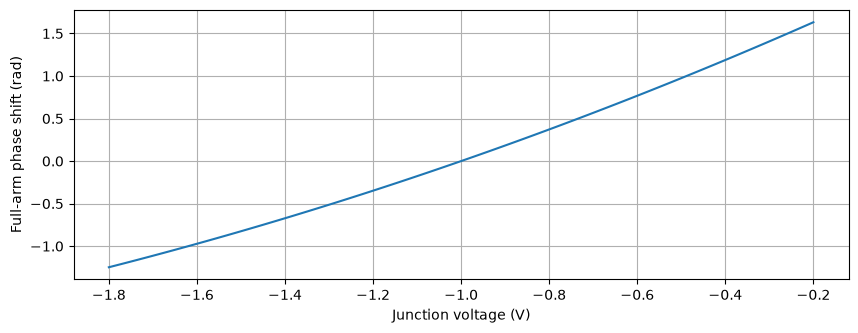

In [4]:
@component(ports=("anode", "cathode", "o1", "o2"), states=("a_forward", "a_reverse", "m_forward", "m_reverse"))
def PNPhaseShifter(  # noqa: N802
    signals,
    length_um=200.0,
    capacitance=64e-15,
    a1=1.2,
    a2=0.15,
    bias=-1.0,
    loss_db_cm=1.0,
    n_group=4.05,
    neff=2.4,
    wavelength_um=1.55,
):
    """Junction charge, quadratic phase and bidirectional native optical delay."""
    past = signals.at_delay(length_um * n_group / (2 * 2.99792458e14))
    half_t = 10 ** (-loss_db_cm * length_um / 10_000 / 40) * jnp.exp(-1j * np.pi * neff * length_um / wavelength_um)
    voltage = (past.anode - past.cathode).real
    phase = length_um * 1e-3 * (a1 * (voltage - bias) + a2 * (voltage**2 - bias**2))
    b1 = half_t * past.m_reverse * jnp.exp(1j * phase)
    b2 = half_t * past.m_forward * jnp.exp(1j * phase)
    charge = capacitance * (signals.anode - signals.cathode)
    return {
        "o1": signals.a_forward - b1,
        "o2": signals.a_reverse - b2,
        "a_forward": signals.o1 - signals.a_forward - b1,
        "a_reverse": signals.o2 - signals.a_reverse - b2,
        "m_forward": signals.m_forward - half_t * past.a_forward,
        "m_reverse": signals.m_reverse - half_t * past.a_reverse,
    }, {"anode": charge, "cathode": -charge}


phase_settings = {
    "length_um": dz * 1e6,
    "capacitance": cj_per_m * dz,
    "a1": phase_a1,
    "a2": phase_a2,
    "bias": v_bias,
    "loss_db_cm": optical_loss_db_cm,
    "n_group": n_opt,
    "wavelength_um": wavelength_um,
}
v_plot = np.linspace(-1.8, -0.2, 101)
plt.plot(v_plot, length_m * 1e3 * (phase_a1 * (v_plot - v_bias) + phase_a2 * (v_plot**2 - v_bias**2)))
plt.xlabel("Junction voltage (V)")
plt.ylabel("Full-arm phase shift (rad)")
plt.show()

In [5]:
def electrode_netlist(*, optical=False):
    """Repeat one section. The electrical view uses the same junction charge."""
    net = {"instances": {"GND": {"component": "ground"}}, "connections": {}, "ports": {}}
    ins, con, ports = net["instances"], net["connections"], net["ports"]
    for k in range(n_sections):
        ins[f"X{k}"] = {"component": "adapter"}
        for mode, model in (("d", "d_line"), ("c", "c_line")):
            left, right = f"{mode}L{k}", f"{mode}R{k}"
            ins[left], ins[right] = {"component": model}, {"component": model}
            con[f"{left},p2"] = f"X{k},{mode}"
            con[f"{right},p1"] = f"X{k},{mode}"
            if k:
                con[f"{left},p1"] = f"{mode}R{k - 1},p2"
            else:
                ports[f"{mode}_in"] = f"{left},p1"
            ports[f"{mode}_out"] = f"{right},p2"
        for arm in ("a", "b"):
            resistor, junction = f"R{arm}{k}", f"PS{arm}{k}"
            ins[resistor] = {"component": "R", "settings": {"R": rj_product / dz}}
            ins[junction] = (
                {"component": "pn", "settings": phase_settings} if optical else {"component": "C", "settings": {"C": cj_per_m * dz}}
            )
            positive, negative = ("anode", "cathode") if optical else ("p1", "p2")
            con[f"{resistor},p1"] = f"X{k},{arm}"
            con[f"{resistor},p2"] = f"{junction},{positive}"
            con[f"{junction},{negative}"] = "GND,p1"
            ports[f"junction_{arm}_{k}"] = f"{junction},{positive}"
    return net


models = {
    **optical_models,
    "adapter": DifferentialAdapter,
    "pn": PNPhaseShifter,
    "C": Capacitor,
    "d_line": half_d,
    "c_line": half_c,
}
# Electrical AC uses the same electrodes and junction capacitances, without optical ports.
electrical = compile_circuit(electrode_netlist(), models, is_complex=False)

## 4. Check the operating point and electrical bandwidth

The driver and terminations belong to the testbench. Keep them outside the reusable MZM. `VD` supplies the differential voltage; `VC` sets the common bias. The junction bias will differ slightly from half the source voltage because the electrodes have resistance and leakage.

Circulax's driven AC interface currently excludes nonlinear mixed optical circuits. Use the electrical view to inspect the same loaded electrode network. It contains each junction capacitance once; the optical view replaces that capacitor with the charge inside `PNPhaseShifter`.

Junction bias along either arm: [-1.04  -1.019 -0.998 -0.977 -0.956 -0.935] V


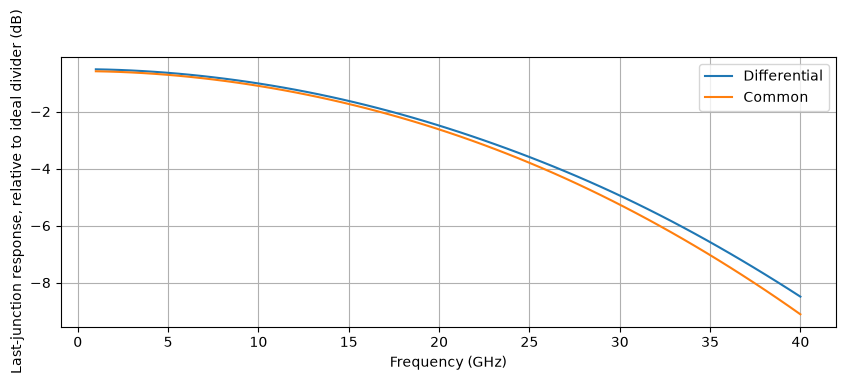

In [6]:
def electrical_bench():
    return {
        "instances": {
            "GND": {"component": "ground"},
            "MZM": {"component": "mzm"},
            "VD": {"component": "drive", "settings": {"dc": 0.0}},
            "VC": {"component": "drive", "settings": {"dc": 2 * v_bias}},
            "RD": {"component": "R", "settings": {"R": 2 * source_r}},
            "RC": {"component": "R", "settings": {"R": source_r / 2}},
            "LD": {"component": "R", "settings": {"R": 2 * load_r}},
            "LC": {"component": "R", "settings": {"R": load_r / 2}},
        },
        "connections": {
            "VD,p1": "RD,p1",
            "RD,p2": "MZM,d_in",
            "MZM,d_out": "LD,p1",
            "VC,p1": "RC,p1",
            "RC,p2": "MZM,c_in",
            "MZM,c_out": "LC,p1",
            "VD,p2": "GND,p1",
            "VC,p2": "GND,p1",
            "LD,p2": "GND,p1",
            "LC,p2": "GND,p1",
        },
        "ports": {f"junction_{arm}_{k}": f"MZM,junction_{arm}_{k}" for arm in ("a", "b") for k in range(n_sections)},
    }


bench_models = {"R": Resistor, "drive": WaveformVoltageSource}
rf = compile_circuit(electrical_bench(), {**bench_models, "mzm": electrical}, is_complex=False)
rf_dc = rf.dc()
bias_a = np.array([float(rf.port(rf_dc, f"junction_a_{k}")) for k in range(n_sections)])
bias_b = np.array([float(rf.port(rf_dc, f"junction_b_{k}")) for k in range(n_sections)])
np.testing.assert_allclose(bias_a, bias_b, atol=1e-8)
print(f"Junction bias along either arm: {bias_a.round(3)} V")
ac_frequencies = jnp.linspace(1e9, 40e9, 61)
fig, ax = plt.subplots()
for source, label in (("VD", "Differential"), ("VC", "Common")):
    ac = rf.ac_response(freqs=ac_frequencies, sources={source: 1.0}, y_dc=rf_dc)
    va = np.asarray(rf.port(ac["solution"], f"junction_a_{n_sections - 1}"))
    vb = np.asarray(rf.port(ac["solution"], f"junction_b_{n_sections - 1}"))
    modal_voltage = va - vb if source == "VD" else (va + vb) / 2
    rejected_voltage = (va + vb) / 2 if source == "VD" else va - vb
    assert np.max(abs(rejected_voltage)) < 1e-7
    ax.plot(np.asarray(ac_frequencies) / 1e9, 20 * np.log10(abs(2 * modal_voltage)), label=label)
ax.set(xlabel="Frequency (GHz)", ylabel="Last-junction response, relative to ideal divider (dB)")
ax.legend()
plt.show()

### Verify RF/optical velocity matching

The optical envelope travels at $c/n_{g,\mathrm{opt}}$. For dispersive RF data, the group index is $n_{g,\mathrm{RF}}=c\,d\beta/d\omega=n_\mathrm{eff}+f\,dn_\mathrm{eff}/df$.

Here the PN junctions add distributed loading, so compare the **loaded** RF propagation with the optical group index. For identical repeated sections, the cell's ABCD matrix gives its Bloch propagation constant through $\cosh(\gamma_\mathrm{loaded}\Delta z)=(A+D)/2$. The calculation below uses the same fitted RLC half-lines and junction R/C as the circuit, over the first propagation band. It includes section discretization.

Matching near the signal band reduces walk-off. The bare-electrode phase index is lower because the junction capacitance slows the RF wave. Compare loaded mode-solver data directly with the optical group index when explicit electrical loading has been omitted.

Differential near 20 GHz: loaded group index 4.012, optical 4.050; walk-off -0.26 ps
Common near 20 GHz: loaded group index 4.004, optical 4.050; walk-off -0.31 ps


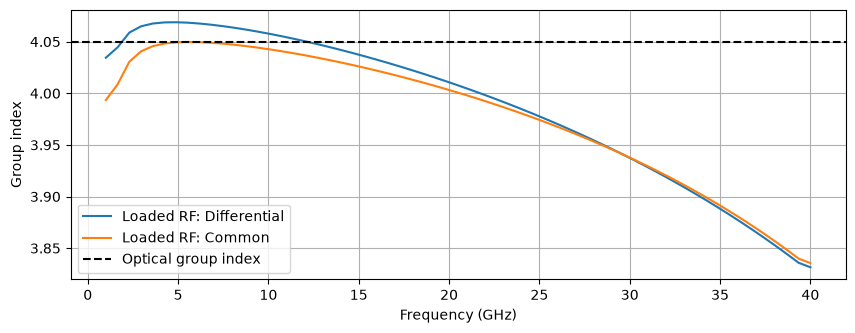

In [7]:
def loaded_group_index(line, scale):
    f = np.asarray(ac_frequencies)
    s_ac = 2j * np.pi * f
    d = dz / 2
    series = np.tile(np.eye(2, dtype=complex), (len(f), 1, 1))
    shunt = series.copy()
    series[:, 0, 1] = line.series.evaluate(f) * d / 2
    shunt[:, 1, 0] = line.shunt.evaluate(f) * d
    half = series @ shunt @ series
    junction = np.tile(np.eye(2, dtype=complex), (len(f), 1, 1))
    junction[:, 1, 0] = s_ac * (cj_per_m * dz / scale) / (1 + s_ac * rj_product * cj_per_m)
    cell = half @ junction @ half
    gamma_loaded = np.arccosh((cell[:, 0, 0] + cell[:, 1, 1]) / 2) / dz
    return c0 * np.gradient(gamma_loaded.imag, 2 * np.pi * f)


fig, ax = plt.subplots()
for label, line, scale in (("Differential", line_d, 2.0), ("Common", line_c, 0.5)):
    group_index = loaded_group_index(line, scale)
    ax.plot(np.asarray(ac_frequencies) / 1e9, group_index, label=f"Loaded RF: {label}")
    design = np.argmin(abs(np.asarray(ac_frequencies) - 20e9))
    walkoff_ps = length_m * (group_index[design] - n_opt) / c0 * 1e12
    print(f"{label} near 20 GHz: loaded group index {group_index[design]:.3f}, optical {n_opt:.3f}; walk-off {walkoff_ps:.2f} ps")
ax.axhline(n_opt, color="k", linestyle="--", label="Optical group index")
ax.set(xlabel="Frequency (GHz)", ylabel="Group index")
ax.legend()
plt.show()

## 5. Assemble the reusable traveling-wave MZM

Replace the simple arm blocks with the repeated PN sections. Keep the original splitter, combiner, matched unused ports and quadrature-bias component. Each adapter drives two physical junctions, so both optical arms are solved in the same circuit.

The MZM exposes optical input/output, differential input/output and common-mode input/output. It contains no laser, driver or electrical termination. The junction-monitor ports are convenient for inspecting the result.

In [8]:
mzm_net = electrode_netlist(optical=True)
optical = optical_netlist()
for arm in ("A", "B"):
    del optical["instances"][f"ARM_{arm}"]
optical["connections"] = {start: end for start, end in optical["connections"].items() if "ARM_" not in start and "ARM_" not in end}
mzm_net["instances"].update(optical["instances"])
mzm_net["connections"].update(optical["connections"])
mzm_net["ports"].update(optical["ports"])
for arm, splitter_port, last_port in (("a", "p3", "COMBINE,p1"), ("b", "p4", "BIAS,p1")):
    mzm_net["connections"][f"SPLIT,{splitter_port}"] = f"PS{arm}0,o1"
    for k in range(n_sections):
        mzm_net["connections"][f"PS{arm}{k},o2"] = f"PS{arm}{k + 1},o1" if k + 1 < n_sections else last_port
mzm = compile_circuit(mzm_net, models, is_complex=True, rtol=1e-9, atol=1e-10)
print("MZM optical and RF ports:", [p for p in mzm.ports if not p.startswith("junction")])

MZM optical and RF ports: ['c_in', 'c_out', 'd_in', 'd_out', 'optical_in', 'optical_out']


## 6. Connect the MZM into an optical link

```text
CW laser → input grating → MZM → output grating → matched optical load
                            ↑
                differential driver + common bias
```

Register the compiled `mzm` in the parent's model dictionary, exactly as for a primitive component. Add the two grating couplers at 1550 nm, each with 3 dB insertion loss. We observe both the MZM output and received power; the gratings' loss therefore stays visible.

The grating model is a wavelength-dependent transmission at a fixed optical carrier; it adds no envelope dispersion in this example.

In [9]:
link_net = electrical_bench()
link_net["instances"].update(
    {
        "LASER": {"component": "laser", "settings": {"power": laser_power}},
        "GRATING_IN": {
            "component": "grating",
            "settings": {"peak_loss_dB": grating_loss_db, "center_wavelength_nm": 1550.0, "wavelength_nm": 1550.0},
        },
        "GRATING_OUT": {
            "component": "grating",
            "settings": {"peak_loss_dB": grating_loss_db, "center_wavelength_nm": 1550.0, "wavelength_nm": 1550.0},
        },
        "OPTICAL_LOAD": {"component": "R", "settings": {"R": 1.0}},
    }
)
link_net["connections"].update(
    {
        "LASER,p1": "GRATING_IN,grating",
        "LASER,p2": "GND,p1",
        "GRATING_IN,waveguide": "MZM,optical_in",
        "MZM,optical_out": "GRATING_OUT,waveguide",
        "GRATING_OUT,grating": "OPTICAL_LOAD,p1",
        "OPTICAL_LOAD,p2": "GND,p1",
    }
)
link_net["ports"].update(output="OPTICAL_LOAD,p1", mzm_output="MZM,optical_out")
link_models = {**bench_models, "mzm": mzm, "laser": OpticalSource, "grating": Grating}
link = compile_circuit(link_net, link_models, is_complex=True, rtol=1e-9, atol=1e-10)
op = link.dc()
received_dc = float(abs(link.port(op, "output")) ** 2)
max_received = laser_power * 10 ** (-(2 * grating_loss_db + optical_loss_db_cm * length_m * 100) / 10)
np.testing.assert_allclose(received_dc, max_received / 2, rtol=1e-6)
print(f"Received power at quadrature: {received_dc * 1e3:.4f} mW")

Received power at quadrature: 0.1199 mW


## 7. Apply 56 Gbaud push-pull data and run the transient

A differential open-circuit source swing of 4 Vpp means **2 Vpp per conductor** about the common bias. Reuse a PRBS7 sequence after a 16-UI constant preamble. The edges last 0.2 UI. A small common-source ripple starts after the preamble; set `common_ripple_vpp=0` for a constant common bias.

The solver initializes from the time-zero source levels and supplies constant prehistory to the delayed components. Native PN history reads propagate the optical fields and evaluate each local voltage at the interaction time. Extract power directly from the output field.

In [10]:
baud, samples_per_ui = 56e9, 32
ui = 1 / baud
sample_dt, integration_dt = ui / samples_per_ui, ui / (2 * samples_per_ui)
preamble_bits, differential_vpp, common_ripple_vpp = 16, 4.0, 0.2
state, pattern = 0x7F, []
for _ in range(127):
    pattern.append(state & 1)
    state = (state >> 1) | (((state ^ (state >> 1)) & 1) << 6)
assert state == 0x7F
assert sum(pattern) == 64
bits = np.r_[np.full(preamble_bits, pattern[0]), pattern]
levels = differential_vpp * (bits - 0.5)
pwl_t, pwl_v = [0.0], [float(levels[0])]
for k in range(1, len(bits)):
    if levels[k] != levels[k - 1]:
        pwl_t.extend([k * ui, (k + 0.2) * ui])
        pwl_v.extend([float(levels[k - 1]), float(levels[k])])
t_stop = len(bits) * ui
pwl_t.append(t_stop)
pwl_v.append(float(levels[-1]))
transient_net = copy.deepcopy(link_net)
transient_net["instances"]["VD"]["settings"] = {"kind": WAVE_PWL, "pwl_t": jnp.asarray(pwl_t), "pwl_v": jnp.asarray(pwl_v)}
transient_net["instances"]["VC"]["settings"] = {
    "kind": WAVE_SIN if common_ripple_vpp else WAVE_DC,
    "dc": 2 * v_bias,
    "offset": 2 * v_bias,
    "amplitude": common_ripple_vpp / 2,
    "freq": 10e9,
    "delay": preamble_bits * ui,
}
transient_link = compile_circuit(transient_net, link_models, is_complex=True, rtol=1e-9, atol=1e-10)
sample_times = jnp.arange(len(bits) * samples_per_ui + 1) * sample_dt
started = time.perf_counter()
solution = transient_link.transient(
    t0=0.0,
    t1=t_stop,
    dt0=integration_dt,
    saveat=sample_times,
    max_steps=int(np.ceil(t_stop / integration_dt)) + 20,
    throw=True,
)
solution.ys.block_until_ready()
power = np.abs(np.asarray(transient_link.port(solution.ys, "output"))) ** 2
mzm_power = np.abs(np.asarray(transient_link.port(solution.ys, "mzm_output"))) ** 2
np.testing.assert_allclose(power, mzm_power * 10 ** (-grating_loss_db / 10), rtol=1e-6, atol=1e-12)
assert np.all(np.isfinite(power))
assert power.max() <= max_received * 1.001
print(f"Transient: {time.perf_counter() - started:.1f} s; {solution.stats['num_steps']} steps")

Transient: 103.9 s; 9152 steps


## 8. Inspect the junction voltages and optical eye

Plot both physical junction voltages to check push-pull operation. Fold the received power over two UI, offset by the known optical flight time. This removes common optical latency while keeping RF propagation, electrical/optical walk-off and waveform distortion. Discard the preamble and first eight data bits.

The normalized eye shows the modulation; the second axis gives received power in mW, including grating and waveguide losses. This is an ideal optical-power observation with no detector noise or receiver equalization.

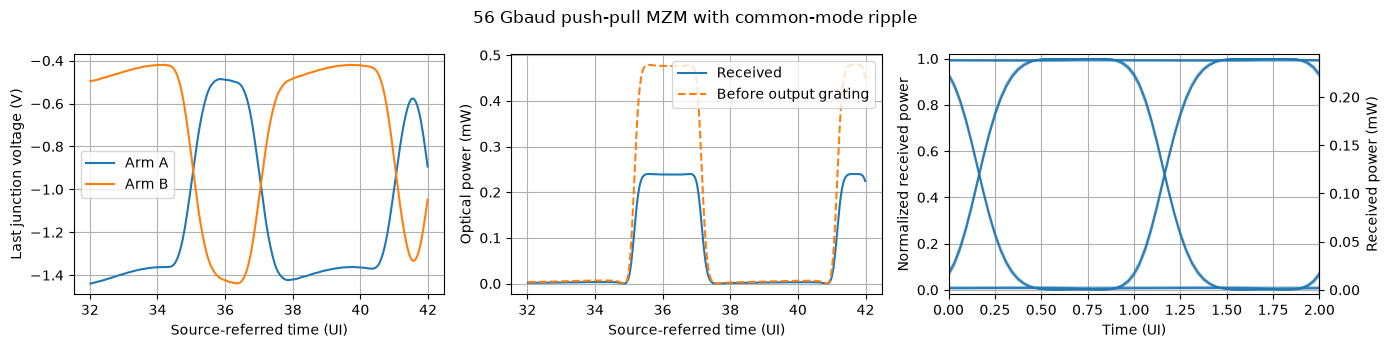

In [11]:
optical_flight = length_m * n_opt / c0
clock = (np.asarray(sample_times) - optical_flight) / ui
window = (clock >= preamble_bits + 16) & (clock <= preamble_bits + 26)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for arm in ("a", "b"):
    voltage = np.asarray(transient_link.port(solution.ys, f"junction_{arm}_{n_sections - 1}")).real
    axes[0].plot(clock[window], voltage[window], label=f"Arm {arm.upper()}")
axes[0].set(xlabel="Source-referred time (UI)", ylabel="Last junction voltage (V)")
axes[0].legend()
axes[1].plot(clock[window], power[window] * 1e3, label="Received")
axes[1].plot(clock[window], mzm_power[window] * 1e3, "--", label="Before output grating")
axes[1].set(xlabel="Source-referred time (UI)", ylabel="Optical power (mW)")
axes[1].legend()
eye_ui = np.arange(2 * samples_per_ui + 1) / samples_per_ui
fold_bits = np.arange(preamble_bits + 8, len(bits) - 5)
query = optical_flight + (fold_bits[:, None] + eye_ui[None, :]) * ui
assert query.max() < float(sample_times[-1])
eye = np.interp(query.ravel(), np.asarray(sample_times), power).reshape(query.shape)
axes[2].plot(eye_ui, (eye / max_received).T, color="C0", alpha=0.15, lw=0.8)
axes[2].set(xlabel="Time (UI)", ylabel="Normalized received power", xlim=(0, 2), ylim=(-0.02, 1.02))
axes[2].secondary_yaxis("right", functions=(lambda x: x * max_received * 1e3, lambda x: x / (max_received * 1e3))).set_ylabel(
    "Received power (mW)"
)
fig.suptitle("56 Gbaud push-pull MZM with common-mode ripple")
plt.tight_layout()
plt.show()

Try changing the modal propagation constants, junction R/C, common-mode ripple or load resistance. Keep the same circuit and rerun from the affected parameter cell. Increase `n_sections` and reduce `integration_dt` to check spatial and temporal convergence for your own data.

The [validation notebook](traveling_wave_mzm_validation.ipynb) contains the full-S reference, vector fitting, ABCD comparisons and RLC-synthesis derivation. The [constant-loss single-ended example](traveling_wave_mzm.ipynb) provides a simpler electrode variant.